# Sampling variability and replicate-aware inference

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation import experiments as exp

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Two different uncertainty questions
First, repeatedly sample cells and rebuild the graph using fixed prescribed velocity vectors. This probes graph/sampling variability, **not velocity-model uncertainty**. The normal intervals and finite-population rescaling are exploratory diagnostics; empirical coverage is reported rather than guaranteed from a small number of datasets.

Second, test condition differences with independent biological-replicate values. Five hundred null simulations and 200 alternatives examine the package's exact permutation test. Cells are not independent experimental units. The p-value table distinguishes independent-group allocations from paired sign flips; paired inference is not implemented by this notebook.


Across-dataset SD: 0.07821451439872044
Observed illustrative interval coverage: 1.0


,seed,estimate,subsample_sd,rescaled_se,lower,upper,covers_nominal_half
0,0,0.449931,0.108217,0.108217,0.237825,0.662037,True
1,1,0.560955,0.087795,0.087795,0.388876,0.733034,True
2,2,0.461936,0.111768,0.111768,0.242871,0.681000,True
3,3,0.537608,0.094552,0.094552,0.352286,0.722931,True
4,4,0.406169,0.109586,0.109586,0.191381,0.620956,True
5,5,0.554118,0.115335,0.115335,0.328061,0.780175,True
6,6,0.394518,0.063430,0.063430,0.270196,0.518841,True
7,7,0.363580,0.100376,0.100376,0.166844,0.560317,True
8,8,0.432932,0.113574,0.113574,0.210327,0.655536,True
9,9,0.602954,0.079040,0.079040,0.448035,0.757873,True


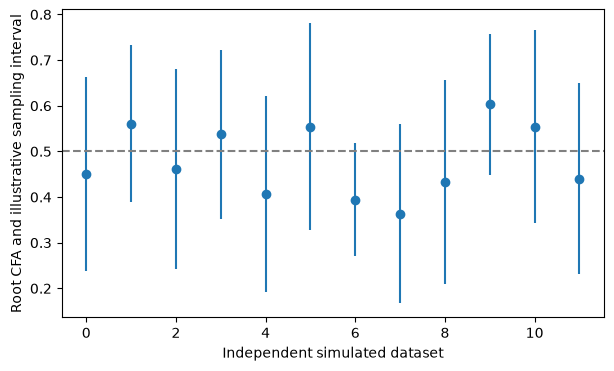

In [3]:
sampling = exp.sampling_uncertainty(n_datasets=12, n_subsamples=20, fraction=0.5)
display(sampling)
print("Across-dataset SD:", sampling.estimate.std())
print("Observed illustrative interval coverage:", sampling.covers_nominal_half.mean())
sampling.to_csv(OUT / "sampling_uncertainty.csv", index=False)
fig, ax = plt.subplots()
ax.errorbar(sampling.seed, sampling.estimate, yerr=1.96 * sampling.rescaled_se, fmt="o")
ax.axhline(0.5, linestyle="--", color="0.5")
ax.set(xlabel="Independent simulated dataset", ylabel="Root CFA and illustrative sampling interval")
plt.show()

In [4]:
from scipy.stats import binomtest

calibration = exp.inference_calibration(n_null=500, n_effect=200, n_replicates=5)
display(calibration.groupby("effect").rejected.agg(["mean", "sum", "count"]))
display(exp.pvalue_floors())
null = calibration[calibration.effect == 0]

interval = binomtest(int(null.rejected.sum()), len(null)).proportion_ci()
print("Null rejection-rate 95% binomial interval:", interval)
calibration.to_csv(OUT / "replicate_test_calibration.csv", index=False)

Null rejection-rate 95% binomial interval: ConfidenceInterval(low=np.float64(0.024601312085545397), high=np.float64(0.06110260938824466))


,mean,sum,count
effect,,,
0.00,0.04,20,500
1.25,0.45,90,200


,replicates_per_group,independent_two_sided_floor,paired_sign_flip_floor
0,2,0.333333,0.500000
1,3,0.100000,0.250000
2,4,0.028571,0.125000
3,5,0.007937,0.062500
4,6,0.002165,0.031250
5,7,0.000583,0.015625
6,8,0.000155,0.007812


## Current safeguards
PairScorer is exercised on independent simulated samples. Complementary two-fate CFA endpoints share one hypothesis. Turning one treated replicate's entire root population into dead ends must raise by default. An explicitly requested exclusion must name the excluded replicate. These assertions verify the default error and the audit trail for explicit exclusions.


In [5]:
complementary, error, dropped, messages = exp.replicate_safeguards()
display(complementary[["fate", "pvalue", "pvalue_adj", "hypothesis_family_size"]])
print("Default undefined-replicate error:", error)
display(dropped[["n_replicates_a", "n_replicates_b", "excluded_replicates"]])
print("Explicit exclusion warnings:", messages)
assert complementary.hypothesis_family_size.eq(1).all()
assert "treated_2" in error
assert dropped.n_replicates_b.iloc[0] == 4
assert null.rejected.mean() < 0.10
print("Replicate safeguards and null-simulation checks passed.")

Default undefined-replicate error: Undefined replicate outcome 'directional_affinity::A' for treated::treated_2. Inspect fate reach and defined-affinity coverage. Use undefined_replicates='drop' only for an explicit conditional analysis.
Explicit exclusion warnings: ["Undefined replicate outcome 'directional_affinity::A' for treated::treated_2. Inspect fate reach and defined-affinity coverage. Use undefined_replicates='drop' only for an explicit conditional analysis."]
Replicate safeguards and null-simulation checks passed.


,fate,pvalue,pvalue_adj,hypothesis_family_size
0,A,0.02381,0.02381,1
1,B,0.02381,0.02381,1


,n_replicates_a,n_replicates_b,excluded_replicates
0,5,4,"[{'condition': 'treated', 'replicate_id': 'tre..."


## Scope
A well-calibrated fixed-graph replicate test does not supply uncertainty for a learned velocity model. Real studies should account for donor pairing, batch structure, graph reconstruction and parameter sensitivity. The coverage experiment uses nominal symmetry as a reference and only twelve realizations; it does not establish generally valid confidence intervals for a nonlinear graph estimator. See [condition inference](https://sccs-py.readthedocs.io/en/latest/condition_inference.html).
